In [6]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

import xgboost as xgb
import shap

import joblib

print("Libraries imported successfully!")

Libraries imported successfully!


In [7]:
df = pd.read_csv("../data/raw/database.csv")

print("Taille :", df.shape)
print("\n--- Types des colonnes ---")
print(df.dtypes)

print("\n--- Valeurs manquantes par colonne ---")
print(df.isnull().sum())

print("\n--- Lignes en double ---")
print(df.duplicated().sum())

df.head()


Taille : (7043, 1)

--- Types des colonnes ---
customerID;gender;SeniorCitizen;Partner;Dependents;tenure;PhoneService;MultipleLines;InternetService;OnlineSecurity;OnlineBackup;DeviceProtection;TechSupport;StreamingTV;StreamingMovies;Contract;PaperlessBilling;PaymentMethod;MonthlyCharges;TotalCharges;Churn    str
dtype: object

--- Valeurs manquantes par colonne ---
customerID;gender;SeniorCitizen;Partner;Dependents;tenure;PhoneService;MultipleLines;InternetService;OnlineSecurity;OnlineBackup;DeviceProtection;TechSupport;StreamingTV;StreamingMovies;Contract;PaperlessBilling;PaymentMethod;MonthlyCharges;TotalCharges;Churn    0
dtype: int64

--- Lignes en double ---
0


,customerID;gender;SeniorCitizen;Partner;Dependents;tenure;PhoneService;MultipleLines;InternetService;OnlineSecurity;OnlineBackup;DeviceProtection;TechSupport;StreamingTV;StreamingMovies;Contract;PaperlessBilling;PaymentMethod;MonthlyCharges;TotalCharges;Churn
0,7590-VHVEG;Female;0;Yes;No;1;No;No phone servi...
1,5575-GNVDE;Male;0;No;No;34;Yes;No;DSL;Yes;No;Y...
2,3668-QPYBK;Male;0;No;No;2;Yes;No;DSL;Yes;Yes;N...
3,7795-CFOCW;Male;0;No;No;45;No;No phone service...
4,9237-HQITU;Female;0;No;No;2;Yes;No;Fiber optic...


In [8]:
%pip install xgboost shap

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [9]:
df = pd.read_csv("../data/raw/database.csv", sep=";")

print("Taille :", df.shape)
print("\n--- Types des colonnes ---")
print(df.dtypes)

print("\n--- Valeurs manquantes par colonne ---")
print(df.isnull().sum())

print("\n--- Lignes en double ---")
print(df.duplicated().sum())

df.head()

Taille : (7043, 21)

--- Types des colonnes ---
customerID              str
gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object

--- Valeurs manquantes par colonne ---
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
St

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [10]:
# Convertir le texte en nombre (les cases vides deviennent NaN)
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

print("Valeurs manquantes dans TotalCharges :", df["TotalCharges"].isnull().sum())
print("Type maintenant :", df["TotalCharges"].dtype)

# Voir les lignes concernées
df[df["TotalCharges"].isnull()][["customerID", "tenure", "MonthlyCharges", "TotalCharges"]]


Valeurs manquantes dans TotalCharges : 11
Type maintenant : float64


,customerID,tenure,MonthlyCharges,TotalCharges
488,4472-LVYGI,0,52.55,NaN
753,3115-CZMZD,0,20.25,NaN
936,5709-LVOEQ,0,80.85,NaN
1082,4367-NUYAO,0,25.75,NaN
1340,1371-DWPAZ,0,56.05,NaN
3331,7644-OMVMY,0,19.85,NaN
3826,3213-VVOLG,0,25.35,NaN
4380,2520-SGTTA,0,20.00,NaN
5218,2923-ARZLG,0,19.70,NaN
6670,4075-WKNIU,0,73.35,NaN


In [11]:
df["TotalCharges"] = df["TotalCharges"].fillna(0)

print("Valeurs manquantes restantes :")
print(df.isnull().sum().sum())


Valeurs manquantes restantes :
0


In [12]:
cat_cols = df.select_dtypes(exclude="number").columns.drop("customerID")

for col in cat_cols:
    print(f"{col} : {df[col].unique().tolist()}")

gender : ['Female', 'Male']
Partner : ['Yes', 'No']
Dependents : ['No', 'Yes']
PhoneService : ['No', 'Yes']
MultipleLines : ['No phone service', 'No', 'Yes']
InternetService : ['DSL', 'Fiber optic', 'No']
OnlineSecurity : ['No', 'Yes', 'No internet service']
OnlineBackup : ['Yes', 'No', 'No internet service']
DeviceProtection : ['No', 'Yes', 'No internet service']
TechSupport : ['No', 'Yes', 'No internet service']
StreamingTV : ['No', 'Yes', 'No internet service']
StreamingMovies : ['No', 'Yes', 'No internet service']
Contract : ['Month-to-month', 'One year', 'Two year']
PaperlessBilling : ['Yes', 'No']
PaymentMethod : ['Electronic check', 'Mailed check', 'Bank transfer (automatic)', 'Credit card (automatic)']
Churn : ['No', 'Yes']


In [13]:
import os

# Churn : Yes/No devient 1/0
df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})

# Créer le dossier de sortie et sauvegarder
os.makedirs("../data/processed", exist_ok=True)
df.to_csv("../data/processed/churn_clean.csv", index=False)

print("Taille :", df.shape)
print("Valeurs manquantes :", df.isnull().sum().sum())
print("\nRépartition de Churn :")
print(df["Churn"].value_counts())
print("\nTaux de churn :", round(df["Churn"].mean() * 100, 1), "%")

Taille : (7043, 21)
Valeurs manquantes : 0

Répartition de Churn :
Churn
0    5174
1    1869
Name: count, dtype: int64

Taux de churn : 26.5 %


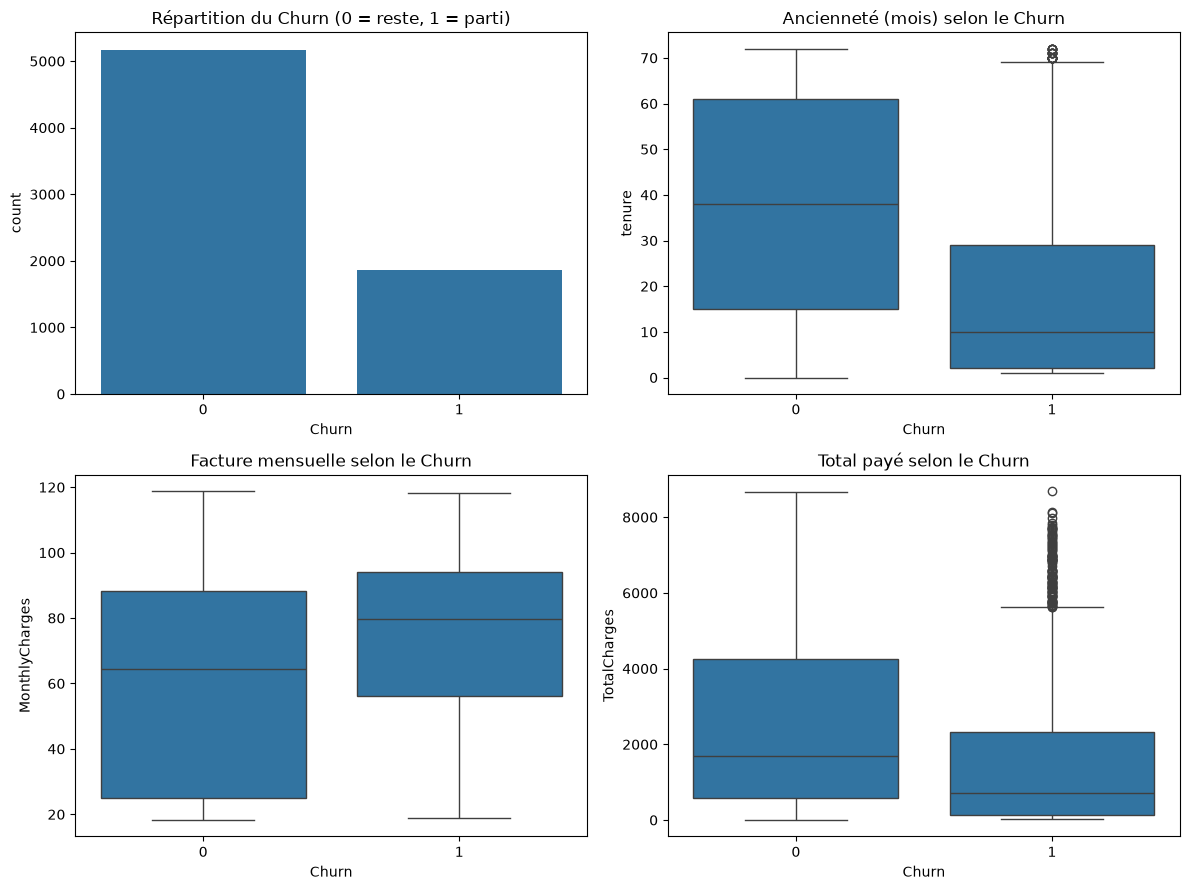

,tenure,MonthlyCharges,TotalCharges
Churn,,,
0,37.6,61.3,2549.9
1,18.0,74.4,1531.8


In [14]:
fig, axes = plt.subplots(2, 2, figsize=(12, 9))

# 1. Répartition du churn
sns.countplot(x="Churn", data=df, ax=axes[0, 0])
axes[0, 0].set_title("Répartition du Churn (0 = reste, 1 = parti)")

# 2. Ancienneté (tenure) selon le churn
sns.boxplot(x="Churn", y="tenure", data=df, ax=axes[0, 1])
axes[0, 1].set_title("Ancienneté (mois) selon le Churn")

# 3. Facture mensuelle selon le churn
sns.boxplot(x="Churn", y="MonthlyCharges", data=df, ax=axes[1, 0])
axes[1, 0].set_title("Facture mensuelle selon le Churn")

# 4. Total payé selon le churn
sns.boxplot(x="Churn", y="TotalCharges", data=df, ax=axes[1, 1])
axes[1, 1].set_title("Total payé selon le Churn")

plt.tight_layout()
plt.show()

# Moyennes par groupe
df.groupby("Churn")[["tenure", "MonthlyCharges", "TotalCharges"]].mean().round(1)

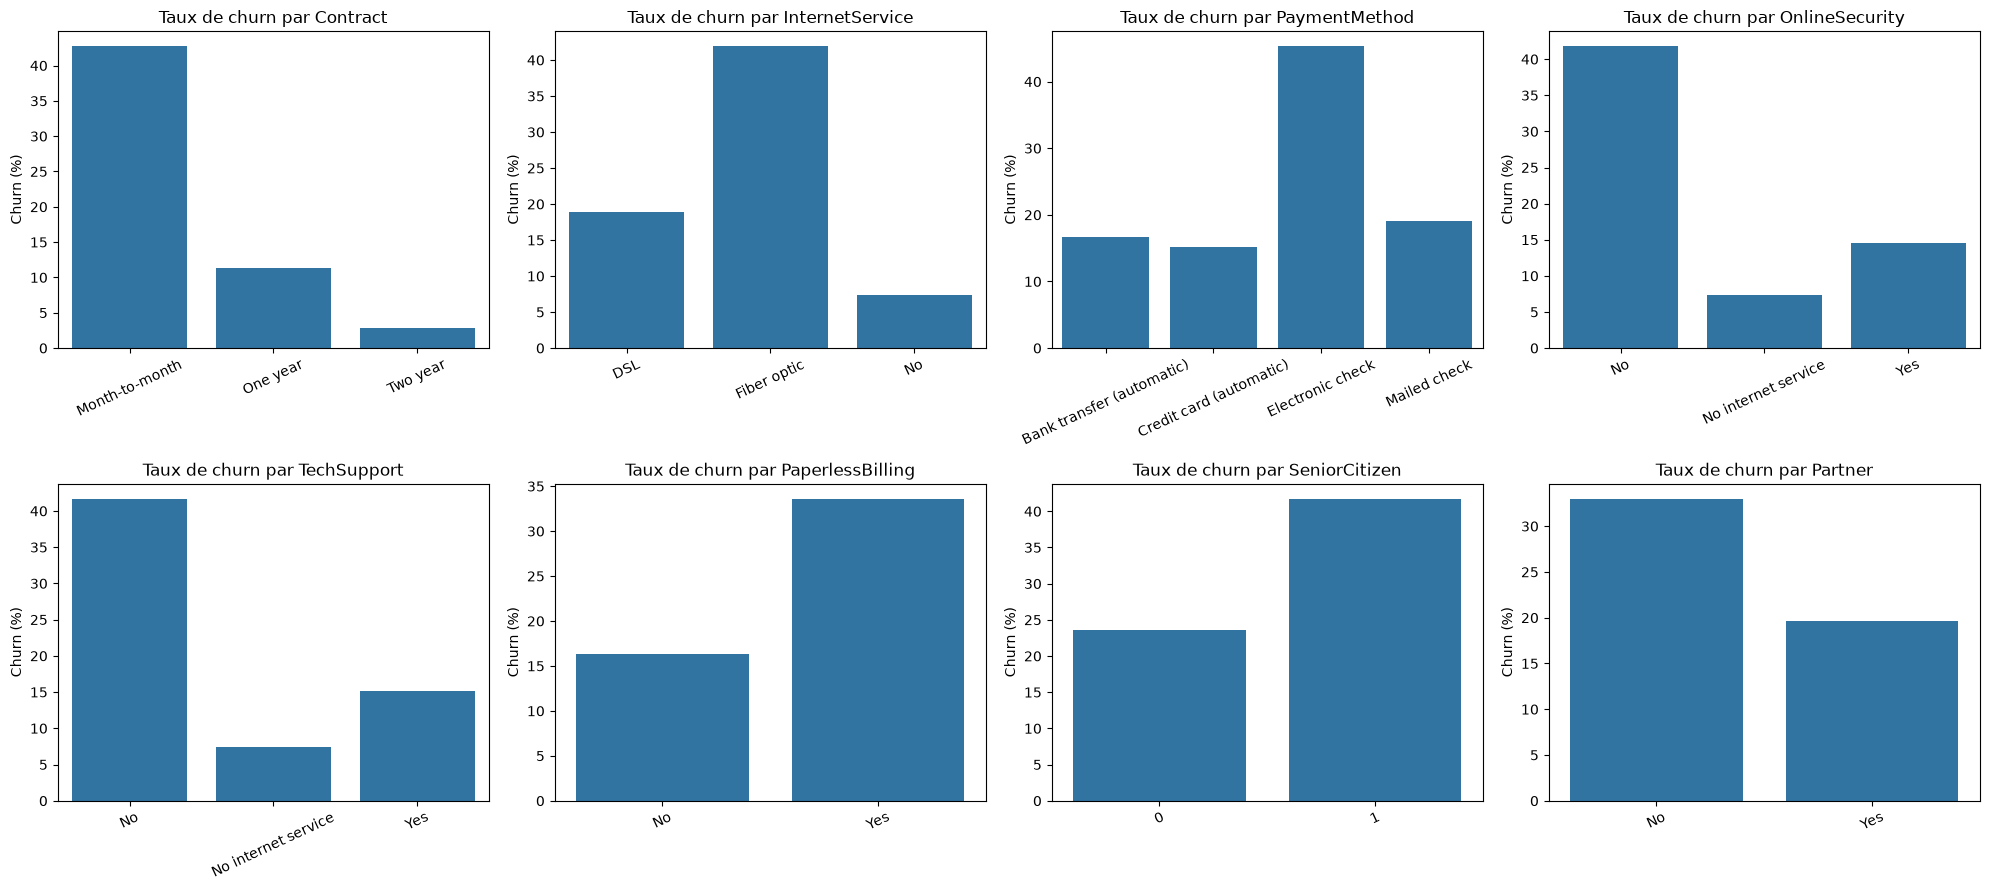

In [15]:
cols = ["Contract", "InternetService", "PaymentMethod", "OnlineSecurity",
        "TechSupport", "PaperlessBilling", "SeniorCitizen", "Partner"]

fig, axes = plt.subplots(2, 4, figsize=(20, 9))

for ax, col in zip(axes.flatten(), cols):
    rate = df.groupby(col)["Churn"].mean() * 100
    sns.barplot(x=rate.index.astype(str), y=rate.values, ax=ax)
    ax.set_title(f"Taux de churn par {col}")
    ax.set_ylabel("Churn (%)")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.show()


In [16]:
# 1. Groupes d'ancienneté
df["tenure_group"] = pd.cut(
    df["tenure"],
    bins=[-1, 12, 24, 48, 72],
    labels=["0-12 mois", "13-24 mois", "25-48 mois", "49-72 mois"]
).astype(str)

# 2. Nombre de services souscrits
services = ["PhoneService", "MultipleLines", "OnlineSecurity", "OnlineBackup",
            "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]
df["nb_services"] = (df[services] == "Yes").sum(axis=1)

# 3. Facture moyenne réelle par mois (évite la division par 0)
df["avg_charges"] = df["TotalCharges"] / df["tenure"].replace(0, 1)

# 4. Client à risque : contrat mensuel + paiement par chèque électronique
df["high_risk"] = (
    (df["Contract"] == "Month-to-month") &
    (df["PaymentMethod"] == "Electronic check")
).astype(int)

print(df[["tenure", "tenure_group", "nb_services", "avg_charges", "high_risk"]].head(10))
print("\nTaux de churn par groupe d'ancienneté :")
print((df.groupby("tenure_group")["Churn"].mean() * 100).round(1))
print("\nTaux de churn high_risk :")
print((df.groupby("high_risk")["Churn"].mean() * 100).round(1))

   tenure tenure_group  nb_services  avg_charges  high_risk
0       1    0-12 mois            1    29.850000          1
1      34   25-48 mois            3    55.573529          0
2       2    0-12 mois            3    54.075000          0
3      45   25-48 mois            3    40.905556          0
4       2    0-12 mois            1    75.825000          1
5       8    0-12 mois            5   102.562500          1
6      22   13-24 mois            4    88.609091          0
7      10    0-12 mois            1    30.190000          0
8      28   25-48 mois            6   108.787500          1
9      62   49-72 mois            3    56.257258          0

Taux de churn par groupe d'ancienneté :
tenure_group
0-12 mois     47.4
13-24 mois    28.7
25-48 mois    20.4
49-72 mois     9.5
Name: Churn, dtype: float64

Taux de churn high_risk :
high_risk
0    16.8
1    53.7
Name: Churn, dtype: float64


In [17]:
from sklearn.model_selection import train_test_split

# 1. Supprimer customerID (un identifiant n'aide pas à prédire)
df_ml = df.drop(columns=["customerID"])

# 2. Sauvegarder la version avec les nouvelles variables (sans encodage)
df_ml.to_csv("../data/processed/churn_features.csv", index=False)

# 3. Encoder les variables texte en 0/1
df_encoded = pd.get_dummies(df_ml, drop_first=True, dtype=int)

# 4. Séparer variables (X) et cible (y)
X = df_encoded.drop(columns="Churn")
y = df_encoded["Churn"]

# 5. Séparer train (80 %) et test (20 %), en gardant la même proportion de churn
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 6. Sauvegarder les 4 fichiers
X_train.to_csv("../data/processed/X_train.csv", index=False)
X_test.to_csv("../data/processed/X_test.csv", index=False)
y_train.to_csv("../data/processed/y_train.csv", index=False)
y_test.to_csv("../data/processed/y_test.csv", index=False)

print("X_train :", X_train.shape)
print("X_test  :", X_test.shape)
print("Churn train :", round(y_train.mean() * 100, 1), "%")
print("Churn test  :", round(y_test.mean() * 100, 1), "%")
print("Valeurs manquantes :", X.isnull().sum().sum())

X_train : (5634, 36)
X_test  : (1409, 36)
Churn train : 26.5 %
Churn test  : 26.5 %
Valeurs manquantes : 0


Accuracy  : 0.735
Precision : 0.501
Recall    : 0.797
F1        : 0.615
ROC-AUC   : 0.842

              precision    recall  f1-score   support

           0       0.91      0.71      0.80      1035
           1       0.50      0.80      0.62       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409



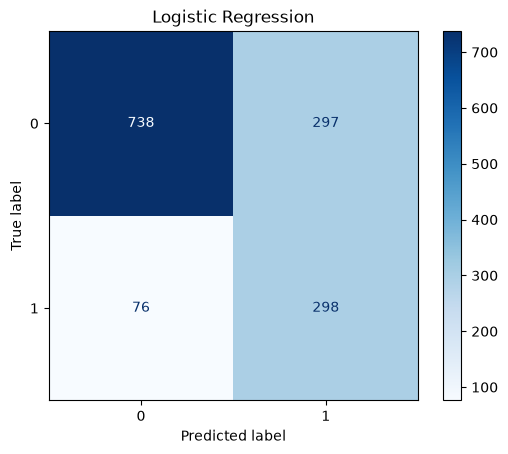

In [18]:
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, classification_report,
                             ConfusionMatrixDisplay)

# 1. Mettre les variables à la même échelle (important pour la régression logistique)
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train)
X_test_sc = scaler.transform(X_test)

# 2. Entraîner le modèle
log_reg = LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42)
log_reg.fit(X_train_sc, y_train)

# 3. Prédire sur le test
y_pred = log_reg.predict(X_test_sc)
y_proba = log_reg.predict_proba(X_test_sc)[:, 1]

# 4. Évaluer
print("Accuracy  :", round(accuracy_score(y_test, y_pred), 3))
print("Precision :", round(precision_score(y_test, y_pred), 3))
print("Recall    :", round(recall_score(y_test, y_pred), 3))
print("F1        :", round(f1_score(y_test, y_pred), 3))
print("ROC-AUC   :", round(roc_auc_score(y_test, y_proba), 3))
print()
print(classification_report(y_test, y_pred))

ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap="Blues")
plt.title("Logistic Regression")
plt.show()

In [19]:
# Fonction qui évalue un modèle et renvoie ses métriques
def evaluer(nom, y_true, y_pred, y_proba):
    return {
        "Modèle": nom,
        "Accuracy": round(accuracy_score(y_true, y_pred), 3),
        "Precision": round(precision_score(y_true, y_pred), 3),
        "Recall": round(recall_score(y_true, y_pred), 3),
        "F1": round(f1_score(y_true, y_pred), 3),
        "ROC-AUC": round(roc_auc_score(y_true, y_proba), 3),
    }

resultats = []

# Résultat de la Logistic Regression (étape 11)
resultats.append(evaluer("Logistic Regression", y_test, y_pred, y_proba))

# 1. Decision Tree (profondeur limitée pour éviter le surapprentissage)
tree = DecisionTreeClassifier(max_depth=5, class_weight="balanced", random_state=42)
tree.fit(X_train, y_train)
resultats.append(evaluer("Decision Tree", y_test,
                         tree.predict(X_test), tree.predict_proba(X_test)[:, 1]))

# 2. Random Forest
rf = RandomForestClassifier(n_estimators=300, max_depth=8, class_weight="balanced",
                            random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
resultats.append(evaluer("Random Forest", y_test,
                         rf.predict(X_test), rf.predict_proba(X_test)[:, 1]))

pd.DataFrame(resultats).set_index("Modèle")

,Accuracy,Precision,Recall,F1,ROC-AUC
Modèle,,,,,
Logistic Regression,0.735,0.501,0.797,0.615,0.842
Decision Tree,0.722,0.485,0.762,0.593,0.815
Random Forest,0.758,0.530,0.786,0.633,0.843


In [20]:
# Poids pour compenser le déséquilibre (clients restés / clients partis)
ratio = (y_train == 0).sum() / (y_train == 1).sum()

xgb_model = xgb.XGBClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=4,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=ratio,
    eval_metric="logloss",
    random_state=42,
)
xgb_model.fit(X_train, y_train)

y_pred_xgb = xgb_model.predict(X_test)
y_proba_xgb = xgb_model.predict_proba(X_test)[:, 1]

resultats.append(evaluer("XGBoost", y_test, y_pred_xgb, y_proba_xgb))

# Tableau de comparaison des 4 modèles
comparaison = pd.DataFrame(resultats).set_index("Modèle").sort_values("ROC-AUC", ascending=False)
comparaison

,Accuracy,Precision,Recall,F1,ROC-AUC
Modèle,,,,,
Random Forest,0.758,0.530,0.786,0.633,0.843
Logistic Regression,0.735,0.501,0.797,0.615,0.842
XGBoost,0.749,0.519,0.783,0.624,0.839
Decision Tree,0.722,0.485,0.762,0.593,0.815


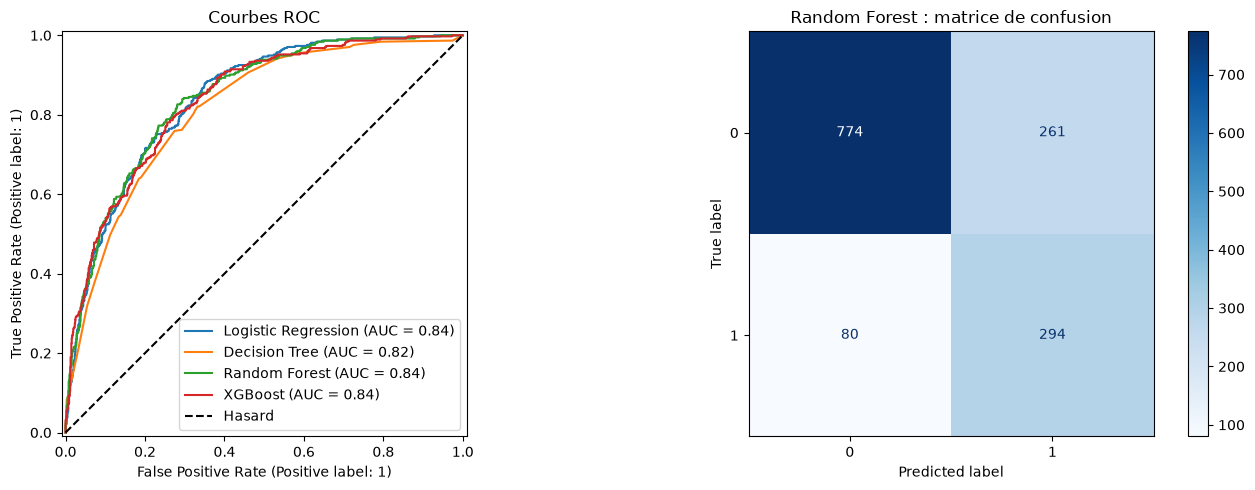

In [21]:
from sklearn.metrics import RocCurveDisplay

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Courbes ROC des 4 modèles
RocCurveDisplay.from_predictions(y_test, y_proba, name="Logistic Regression", ax=axes[0])
RocCurveDisplay.from_predictions(y_test, tree.predict_proba(X_test)[:, 1], name="Decision Tree", ax=axes[0])
RocCurveDisplay.from_predictions(y_test, rf.predict_proba(X_test)[:, 1], name="Random Forest", ax=axes[0])
RocCurveDisplay.from_predictions(y_test, y_proba_xgb, name="XGBoost", ax=axes[0])
axes[0].plot([0, 1], [0, 1], "k--", label="Hasard")
axes[0].set_title("Courbes ROC")
axes[0].legend()

# 2. Matrice de confusion du meilleur modèle (Random Forest)
ConfusionMatrixDisplay.from_estimator(rf, X_test, y_test, cmap="Blues", ax=axes[1])
axes[1].set_title("Random Forest : matrice de confusion")

plt.tight_layout()
plt.show()